# Explore the cost and limits of width smoothing

**Question:** How do target width and schedule choice affect slivers removed, capacity-blocked moves, and signed NPV change?

**Level:** 2 · The method in practice

**Prerequisites:** Complete topic 01, CPIT scheduling and bounds.

**Reading time:** 28 minutes

## Objectives

This lesson studies trade-offs rather than treating width smoothing as free cleanup. On one fixed synthetic case, it applies three width targets to the same feasible schedule and compares another schedule under the same target. For every result, the report distinguishes narrow blocks found, blocks actually moved, moves blocked by resource capacity, and the change in NPV. Package controls verify the returned schedule. The experiment shows why an unchanged minimum run length does not mean the routine did nothing: isolated slivers may have no eligible neighbour, and capacity may prevent a move. It also makes the limitation explicit: smoothing cannot recover capacity lost to a constrained receiving period, and its block-count proxy does not establish physical access, slope stability, or equipment geometry.

## Setup

Install the pinned environment from the repository root with `pip install oreblocks==0.6.6 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2`. `oreblocks==0.6.6`.

```bash
pip install oreblocks==0.6.6 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2
```

In [1]:
# Load the PhaseFlow instance pipeline and OreBlocks geometry methods.
import importlib.metadata as metadata
import sys
from pathlib import Path
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case, DepositSpec, Scenario
from pipeline.model.instances import build_instance
import oreblocks as ob
print('oreblocks', metadata.version('oreblocks'))

oreblocks 0.6.6


## Data

The declared input is generated by PhaseFlow's MIT-licensed pipeline: synthetic porphyry twin, dimensions 8×8×4, fixed seed 41, six periods and two resource limits. The pipeline supplies block coordinates, precedence, grade and tonnage. OreBlocks 0.6.6 computes the schedule, coherence metrics and width smoothing. No published MineLib block model is used. The width target is in grid blocks because this case has no surveyed block dimension; never convert it to metres without a declared grid size. The Bai et al. source discusses approximately 100 m as a mining-width target in a different pushback-design model. That value is context, not the target of this synthetic schedule.

## Method



### Step 1: build the case



In [2]:
# Generate one seeded synthetic case through the PhaseFlow pipeline.
case = Case(
    id='operability-porphyry-8x8x4', category='teaching',
    title_en='Porphyry coherence lesson', title_es='Leccion de coherencia porfídica',
    deposit=DepositSpec(kind='twin', archetype='porphyry', dims=(8, 8, 4), seed=41),
    scenario=Scenario(periods=6, discount_rate=0.08,
        capacity_fraction=(0.85, 0.55), resource_names=('mining', 'processing')),
)
instance = build_instance(case)
print('contract accepted:', instance.report.ok, '| blocks:', instance.n_blocks)

contract accepted: True | blocks: 256


### Step 1: compare starting schedules

The starting schedule affects which neighbour periods can receive a narrow block. We compare two method-generated plans on this same input; neither is chosen using the width result.

In [3]:
# Generate a feasible Expected schedule as the shared starting plan.
expected, _ = ob.solve_cpit(
    instance.cpit, instance.precedence,
    method='expected', local_search=False,
)
print(expected.method, round(expected.npv, 2))

toposort:expected[r1] 6241283.54


Generate a second schedule with the greedy priority rule. Its value and geometry may differ because its extraction ordering differs.

In [4]:
# Generate a separate feasible schedule with the greedy priority rule.
greedy, _ = ob.solve_cpit(
    instance.cpit, instance.precedence,
    method='greedy', local_search=False,
)
print(greedy.method, round(greedy.npv, 2))

toposort:greedy 3314787.03


### Step 2: vary the target width



In [5]:
# Apply three target widths to the same feasible schedule.
reports = []
for width in (2, 3, 4):
    result, summary = ob.enforce_min_width(
        instance.cpit, expected, instance.x, instance.y,
        instance.level, instance.precedence, target_width=width,
    )
    reports.append((width, result, summary))
print([(width, summary.moved_blocks, summary.blocked_by_capacity) for width, _, summary in reports])

[(2, 25, 29), (3, 25, 29), (4, 25, 32)]


Use the package controls on each smoothed result. A passing control supports modeled capacity and precedence feasibility; it does not validate access geometry or geotechnical conditions.

In [6]:
# Verify every width result with independent package controls.
for width, result, summary in reports:
    controls = ob.run_controls(instance.cpit, instance.precedence, result)
    print(width, '| feasible:', controls.__dict__, '| NPV cost %:', round(summary.npv_cost_pct, 4))

2 | feasible: {'duality_set_matches': True, 'duality_bound_error': 0.0, 'bound_geq_feasible': True, 'order_invariant': True, 'order_invariance_error': 0.0} | NPV cost %: -0.0706
3 | feasible: {'duality_set_matches': True, 'duality_bound_error': 0.0, 'bound_geq_feasible': True, 'order_invariant': True, 'order_invariance_error': 0.0} | NPV cost %: -0.0706
4 | feasible: {'duality_set_matches': True, 'duality_bound_error': 0.0, 'bound_geq_feasible': True, 'order_invariant': True, 'order_invariance_error': 0.0} | NPV cost %: -0.0706


Plot the reduction in narrow blocks against the signed NPV change for each target. This exposes the engineering trade-off without collapsing it into one score.

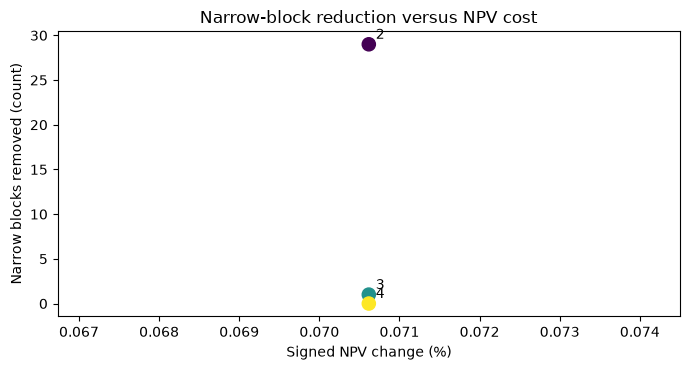

In [7]:
# Plot narrow-run reduction against value cost for each target.
widths = [row[0] for row in reports]
reductions = [row[2].below_target_before - row[2].below_target_after for row in reports]
changes = [-row[2].npv_cost_pct for row in reports]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.scatter(changes, reductions, c=widths, cmap='viridis', s=90)
for target_cost, reduction, width in zip(changes, reductions, widths):
    ax.annotate(str(width), (target_cost, reduction), xytext=(5, 4), textcoords='offset points')
ax.set(
    title='Narrow-block reduction versus NPV cost',
    xlabel='Signed NPV change (%)', ylabel='Narrow blocks removed (count)',
)
fig.tight_layout()
plt.show()

### Figure 1

Each point is one target width on the same schedule. The labels identify the target in blocks. A point farther up represents a greater reduction in narrow blocks; farther right means a larger NPV gain (or a smaller loss). This is a measured trade-off, not a universal optimum. Targets that do not move blocks can still incur different classifications, and no point establishes physical access or stability.

Now compare capacity refusals across the three runs. A move can be geometrically attractive yet remain blocked because the receiving period has no room across all resources.

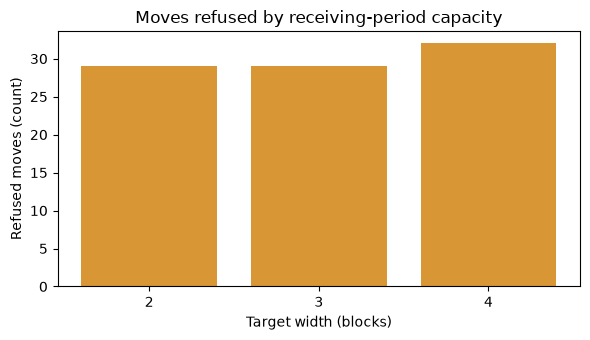

In [8]:
# Plot the moves refused by receiving-period capacity for each target.
blocked = [row[2].blocked_by_capacity for row in reports]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar([str(width) for width in widths], blocked, color='#d99635')
ax.set(
    title='Moves refused by receiving-period capacity',
    xlabel='Target width (blocks)', ylabel='Refused moves (count)',
)
fig.tight_layout()
plt.show()

### Figure 2

The bars count requested moves refused because the receiving period lacked room in at least one resource. They explain why increasing the target does not guarantee a corresponding width improvement. Zero refusals would not prove that all narrow runs were removed: isolated blocks may lack a majority neighbour, and precedence may rule out a move. The NPV and feasibility records remain necessary alongside this count.

Width targets can reduce narrow runs while changing connectedness; measure each resulting period map to interpret that trade-off.

In [9]:
# Measure connected runs for each returned width alternative.
coherence_by_width = {
    width: ob.schedule_coherence(
        result.period_of_block, instance.x, instance.y,
        instance.level, instance.cpit.n_periods,
    )
    for width, result, summary in reports
}
print({width: [(row.components, row.min_width_blocks) for row in rows]
       for width, rows in coherence_by_width.items()})


{2: [(1, 1), (4, 1), (4, 1), (3, 1), (6, 1), (3, 1)], 3: [(1, 1), (4, 1), (4, 1), (3, 1), (6, 1), (3, 1)], 4: [(1, 1), (4, 1), (4, 1), (3, 1), (6, 1), (3, 1)]}


The width target is a post-process preference applied to an already feasible period schedule. It tries to move narrow mined runs into neighboring periods while preserving precedence and resource limits. That makes the report's refused moves meaningful: they identify where operational smoothing conflicts with a receiving period's capacity. A high refusal count is not a solver failure; it can show that the requested geometry is incompatible with the available slack.

Read the three outputs together. The number of blocks below target measures the geometric objective, the connected-component count describes fragmentation at the period-map scale, and signed NPV change measures the economic cost under the model's discounting and value assumptions. None is a substitute for the others. A target can reduce narrow runs while leaving component count unchanged, or improve continuity at a measurable value cost. The width heuristic is local and its reports are tied to the starting schedule, so it does not prove the globally best operable plan.

There is no guarantee that increasing the target from two to three to four monotonically improves every metric. Each target changes which moves are proposed and which capacity constraints bind; a larger request can encounter more refusals or choose a different sequence of accepted moves. Likewise, the NPV change is not a realized mining cost. It omits equipment, access, geotechnical, and sequencing costs that are not encoded in this instance. For a real planning study, sweep targets on the same baseline, inspect the period maps and refusal reasons, then evaluate the small set of operationally plausible alternatives with the mine's detailed design criteria.


## Results

**Answer:** At target width 3, the report moves 25 blocks, refuses 29 on capacity, and reduces below-width blocks from 90 to 89. The signed NPV change is +0.0706% (a gain, not a cost); package controls confirm modeled CPIT feasibility, not physical mine operability.

In [10]:
# Report the target-three values used to answer the question.
selected = next(summary for width, result, summary in reports if width == 3)
print(f'moved={selected.moved_blocks}; blocked={selected.blocked_by_capacity}')
print(f'below_width={selected.below_target_before}->{selected.below_target_after}')
print(f'npv_change_pct={-selected.npv_cost_pct:.4f}')

moved=25; blocked=29
below_width=90->89
npv_change_pct=0.0706


## Summary

You compared target widths and a second starting schedule using identical inputs. The trade-off is case-specific: target width changes the desired geometry, but capacity and precedence decide which moves can occur. A post-process cannot make an infeasible plan feasible, cannot certify a geotechnical design, and cannot guarantee a minimum physical width. For a real case, map grid blocks to metres, include roads and phase access, check all resource limits, and have mine-planning engineers review the resulting sequence.

## References

- OreBlocks 0.6.6: `oreblocks.schedule_coherence`, `oreblocks.enforce_min_width`.
- Chicoisne et al. (2012), multi-period open-pit planning: https://doi.org/10.1287/opre.1120.1050.
- Bai et al. (2018), minimum mining width and pushback design: https://doi.org/10.17159/2411-9717/2018/v118n5a8.
- PhaseFlow method evidence: `docs/methodologies/10_operability.md`.